<a href="https://colab.research.google.com/github/duartegonzaloariel/UDELAR_Astrometric-calibration-/blob/main/03_ensemble_todas_las_estaciones.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 · Ensemble single + multi en todas las estaciones

Corre automáticamente, para cada modelo de `MODELOS` y cada estación de `ESTACIONES`:
entrenamiento single-station → combinación con el multi-station ya entrenado en el notebook 02 → bootstrap y controles → fila de la Tabla 9.

**Requisitos (del notebook 02):** `split_seed42.csv` y `pred_<MODELO>_global.csv` en Drive para cada modelo.

Al final: Tabla 9 por modelo, resumen de toda la red (todas las estrellas de test juntas, con bootstrap), error por cenit y comparación entre modelos. Todo se guarda en `resultados_ensemble/`.

# 0. Inicialización

In [2]:
import os, copy, math, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from scipy.optimize import least_squares
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
from IPython.display import display
from google.colab import drive
drive.mount('/content/drive')

pd.set_option('display.max_columns', None); pd.set_option('display.max_rows', 200); pd.set_option('display.width', None)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
display(pd.DataFrame({'device': [str(device)],
                      'gpu': [torch.cuda.get_device_name(0) if torch.cuda.is_available() else '-']}))

Mounted at /content/drive


,device,gpu
0,cpu,-


## 0.1. Configuración

In [3]:
PATH_BASE     = "/content/drive/MyDrive/InvestigacionesPropias/Fireball/estrellas/calibracion/"
ARCHIVO_DATOS = "df_global_con_ajuste.csv"     # salida del notebook 01

MODELOS    = ['DENSE', 'CNN', 'DENSE_BAYESIAN']                          # los multi deben existir (notebook 02)
ESTACIONES = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 16, 17, 19, 20]

LOOPS    = 5
EPOCHS   = 1000
PATIENCE = 50
BATCH    = 32
LR       = 1e-3
BETA_KL  = 0.01           # solo DENSE_BAYESIAN

SEED_SPLIT = 42           # el mismo que en el notebook 02
USAR_FECHA = False        # igual que en el notebook 02
N_BOOT     = 1000
W_GRID     = np.round(np.arange(0, 1.0001, 0.05), 2)

STATION_ONEHOT_COLS = [f'station_{s}' for s in [1,2,3,4,5,6,7,8,9,10,12,13,14,15,16,17,19,20]]
CARPETA = os.path.join(PATH_BASE, "resultados_ensemble")
os.makedirs(CARPETA, exist_ok=True)

faltan = [m for m in MODELOS if not os.path.exists(os.path.join(PATH_BASE, f"pred_{m}_global.csv"))]
assert not faltan, f"Falta correr el multi-station (notebook 02) de: {faltan}"
display(pd.DataFrame({'modelos': [MODELOS], 'estaciones': [len(ESTACIONES)], 'LOOPS': [LOOPS], 'salida': [CARPETA]}))

,modelos,estaciones,LOOPS,salida
0,"[DENSE, CNN, DENSE_BAYESIAN]",18,5,/content/drive/MyDrive/InvestigacionesPropias/...


# 1. Datos, split y ajuste clásico (idéntico al notebook 02)

In [4]:
df = pd.read_csv(os.path.join(PATH_BASE, ARCHIVO_DATOS))
df = df[(~df['excluida']) & (~df['outlier'])].reset_index(drop=True)
df['rid'] = np.arange(len(df))

sp = pd.read_csv(os.path.join(PATH_BASE, f"split_seed{SEED_SPLIT}.csv"))
assert len(sp) == len(df), "El split guardado no coincide con los datos."
df['split'] = sp['split'].values
display(df['split'].value_counts().to_frame('N').T)

split,train,test,val
N,5474,1714,1370


In [5]:
K = 60 * 180 / np.pi        # rad -> arcmin

def vec(z_deg, a_deg):
    z, a = np.deg2rad(z_deg), np.deg2rad(a_deg)
    return np.stack([np.sin(z)*np.cos(a), np.sin(z)*np.sin(a), np.cos(z)], axis=-1)

def to_za(v):
    v = v / np.linalg.norm(v, axis=-1, keepdims=True)
    return np.rad2deg(np.arccos(np.clip(v[..., 2], -1, 1))), np.rad2deg(np.arctan2(v[..., 1], v[..., 0])) % 360

def sep_arcmin(v1, v2):
    return np.rad2deg(np.arccos(np.clip(np.sum(v1*v2, axis=-1), -1, 1))) * 60

def modelo(p, x, y, paridad, devolver_camara=False):
    x0, y0, a0, p1, p2, p3, eps, E = p
    dx, dy = x - x0, y - y0
    r = np.hypot(dx, dy)
    phi = np.rad2deg(np.arctan2(dy, dx))
    zc = p1*r + p2*r**2 + p3*r**3
    v = vec(zc, a0 + paridad*phi)
    e, t = np.deg2rad(E), np.deg2rad(eps)
    Rz = lambda g: np.array([[np.cos(g), -np.sin(g), 0], [np.sin(g), np.cos(g), 0], [0, 0, 1]])
    Ry = np.array([[np.cos(t), 0, np.sin(t)], [0, 1, 0], [-np.sin(t), 0, np.cos(t)]])
    v = v @ (Rz(e) @ Ry @ Rz(-e)).T
    if devolver_camara:
        return v, zc, paridad*phi, r
    return v

def ajustar(x, y, z, a):
    v_obs = vec(z, a)
    cx, cy = np.median(x), np.median(y)
    r0 = np.hypot(x - cx, y - cy)
    p1_0 = np.sum(r0*z) / np.sum(r0**2)
    mejor = None
    for par in (+1, -1):
        phi0 = np.rad2deg(np.arctan2(y - cy, x - cx))
        d = np.deg2rad(a - par*phi0)
        a0_0 = np.rad2deg(np.arctan2(np.sin(d).mean(), np.cos(d).mean()))
        f = lambda p: (modelo(p, x, y, par) - v_obs).ravel()
        res = least_squares(f, [cx, cy, a0_0, p1_0, 0.0, 0.0, 0.5, 0.0],
                            x_scale=[50, 50, 10, p1_0, p1_0/500, p1_0/2.5e5, 1, 30],
                            loss='soft_l1', f_scale=np.deg2rad(0.5), max_nfev=4000)
        err = sep_arcmin(modelo(res.x, x, y, par), v_obs)
        if mejor is None or np.median(err) < np.median(mejor['err']):
            mejor = dict(p=res.x, paridad=par, err=err)
    return mejor

def base_tangente(z_deg, a_deg):
    """Vectores unitarios en la dirección de z creciente (e_z) y de azimut creciente (e_a)."""
    z, a = np.deg2rad(z_deg), np.deg2rad(a_deg)
    e_z = np.stack([np.cos(z)*np.cos(a), np.cos(z)*np.sin(a), -np.sin(z)], axis=-1)
    e_a = np.stack([-np.sin(a), np.cos(a), np.zeros_like(a)], axis=-1)
    return e_z, e_a

def reconstruir(v_cl, e_z, e_a, t):
    """Clásico + residuo (t = [Δz, Δa·sin z] en arcmin) -> vector unitario predicho."""
    v = v_cl + (t[:, [0]] * e_z + t[:, [1]] * e_a) / K
    return v / np.linalg.norm(v, axis=-1, keepdims=True)

In [6]:
df['zenith'] = 90.0 - df['altitude']
v_true = vec(df['zenith'].values, df['azimuth'].values)
v_cl = np.zeros_like(v_true)
for c in ['z_cam', 'phi_cam', 'r_px']:
    df[c] = np.nan

PARAMS_CLASICO, filas = {}, []
for camp, g in df.groupby('campaña'):
    tr = g[g['split'] == 'train']
    fit = ajustar(tr['Posicion_X'].values.astype(float), tr['Posicion_Y'].values.astype(float),
                  tr['zenith'].values, tr['azimuth'].values)
    PARAMS_CLASICO[camp] = dict(p=fit['p'].tolist(), paridad=int(fit['paridad']))
    v, zc, phic, r = modelo(fit['p'], g['Posicion_X'].values.astype(float), g['Posicion_Y'].values.astype(float),
                            fit['paridad'], devolver_camara=True)
    v_cl[g.index.values] = v
    df.loc[g.index, 'z_cam'], df.loc[g.index, 'phi_cam'], df.loc[g.index, 'r_px'] = zc, phic, r
    e = sep_arcmin(v, v_true[g.index.values])
    m_te = (g['split'] == 'test').values
    filas.append(dict(campaña=camp, N=len(g), N_train=len(tr), paridad=fit['paridad'],
                      escala=fit['p'][3]*60, x0=fit['p'][0], y0=fit['p'][1], incl=abs(fit['p'][6]),
                      clasico_train_med=np.median(e[~m_te]), clasico_test_med=np.median(e[m_te]),
                      caldas_test_med=g.loc[m_te, 'err_caldas'].median()))

df['z_cl'], df['a_cl'] = to_za(v_cl)
e_z, e_a = base_tangente(df['z_cl'].values, df['a_cl'].values)
df['t_z'] = np.sum(v_true * e_z, axis=1) * K       # residuo en cenit (arcmin)
df['t_a'] = np.sum(v_true * e_a, axis=1) * K       # residuo en azimut · sin z (arcmin)
df['err_clasico'] = sep_arcmin(v_cl, v_true)

display(pd.DataFrame(filas).set_index('campaña').round(2))

,N,N_train,paridad,escala,x0,y0,incl,clasico_train_med,clasico_test_med,caldas_test_med
campaña,,,,,,,,,,
10_2023-02,197,126,-1,6.51,787.02,533.60,1.66,5.74,4.14,12.80
10_2023-05,222,142,-1,6.50,787.20,534.33,4.60,5.13,4.99,9.07
12_2023-05,354,226,-1,6.42,800.67,479.83,1.50,12.66,12.68,13.97
13_2023-03,354,226,-1,6.41,794.89,443.30,1.69,5.92,6.35,9.03
14_2023-02,341,218,-1,6.50,783.85,498.43,2.19,5.69,6.66,14.34
15_2023-02,396,254,-1,6.47,768.62,492.56,2.34,5.13,4.57,9.20
16_2023-05,180,115,-1,6.46,791.80,502.69,3.22,5.18,5.00,13.65
17_2023-03,350,224,-1,6.50,804.51,488.41,1.46,6.34,6.08,9.12
19_2023-05,154,98,-1,6.47,820.74,476.77,2.18,6.13,7.34,17.83


In [7]:
for col in STATION_ONEHOT_COLS:
    df[col] = (df['station'] == int(col.split('_')[1])).astype(int)
df['sin_phi_cam'], df['cos_phi_cam'] = np.sin(np.deg2rad(df['phi_cam'])), np.cos(np.deg2rad(df['phi_cam']))
df['sin_a_cl'],   df['cos_a_cl']    = np.sin(np.deg2rad(df['a_cl'])),    np.cos(np.deg2rad(df['a_cl']))
df['mes_sin'], df['mes_cos'] = np.sin(2*np.pi*df['mes']/12), np.cos(2*np.pi*df['mes']/12)

CONT_FEATURES = ['z_cam', 'sin_phi_cam', 'cos_phi_cam', 'z_cl', 'sin_a_cl', 'cos_a_cl']
if USAR_FECHA:
    CONT_FEATURES += ['año', 'mes_sin', 'mes_cos']
COLUMNS_DATA   = CONT_FEATURES + STATION_ONEHOT_COLS
COLUMNS_TARGET = ['t_z', 't_a']
OUTPUT_SIZE    = len(COLUMNS_TARGET)
criterion = nn.MSELoss()

# 2. Modelos y entrenamiento (sin cambios)

In [8]:
class SkyCoordinatesModel(nn.Module):
    def __init__(self, input_size, output_size):
        super(SkyCoordinatesModel, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Linear(128, 256),

            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, output_size)
        )

    def forward(self, x):

        return self.network(x)

    def predict_with_uncertainty(self, x, n_samples=30):
        """
        NUEVO: incertidumbre vía MC-Dropout. A diferencia del modelo
        Bayesiano (que usa LayerNorm, indiferente a train/eval), este
        modelo tiene BatchNorm1d: llamar self.train() a secas activaría
        también el BatchNorm en modo batch-stats, corrompiendo sus
        estadisticas acumuladas (running_mean/running_var) como efecto
        secundario, incluso dentro de no_grad(). Por eso el modelo se deja
        en eval() (BatchNorm usa sus stats acumuladas, sin tocarlas) y se
        fuerza SOLO el Dropout a modo train, a mano.
        Devuelve (media, desvio_estandar) por muestra, igual formato que
        BayesianSkyCoordinatesModel.predict_with_uncertainty().
        """
        self.eval()
        for module in self.modules():
            if isinstance(module, nn.Dropout):
                module.train()

        preds = []
        with torch.no_grad():
            for _ in range(n_samples):
                preds.append(self.forward(x))
        preds = torch.stack(preds, dim=0)  # (n_samples, batch, output_size)
        mean = preds.mean(dim=0)
        std  = preds.std(dim=0)

        self.eval()  # restaurar todo (dropout incluido) a eval limpio
        return mean, std


In [9]:
# --- Corrección completa (robusta y lista para usar) ---
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class BayesianLinear(nn.Module):
    def __init__(self, in_features, out_features, init_logvar=-8.0, prior_var=1.0):
        super().__init__()
        # Medias
        self.weight_mu = nn.Parameter(torch.zeros(out_features, in_features))
        self.bias_mu   = nn.Parameter(torch.zeros(out_features))
        # Varianzas log (menos extremas que -10 para permitir aprender incertidumbre)
        self.weight_logvar = nn.Parameter(torch.ones(out_features, in_features) * init_logvar)
        self.bias_logvar   = nn.Parameter(torch.ones(out_features) * init_logvar)

        # NUEVO: prior de los pesos, Normal(0, prior_var). Se usa en kl_divergence().
        self.prior_var = prior_var

    def forward(self, x):
        if self.training:
            # Reparametrización: mu + sigma * eps (solo durante el entrenamiento,
            # necesario para propagar gradientes a través del sampling)
            weight_std = torch.exp(0.5 * self.weight_logvar)
            bias_std   = torch.exp(0.5 * self.bias_logvar)

            weight = self.weight_mu + weight_std * torch.randn_like(weight_std)
            bias   = self.bias_mu   + bias_std   * torch.randn_like(bias_std)
        else:
            # En evaluación usamos la media de la posterior (predicción determinista,
            # comparable con Dense/CNN en vez de variar en cada llamada)
            weight = self.weight_mu
            bias   = self.bias_mu

        return F.linear(x, weight, bias)

    def kl_divergence(self):
        """
        NUEVO: KL(q(w) || p(w)) entre la posterior aprendida (weight_mu,
        weight_logvar) y un prior Normal(0, prior_var), sumada sobre todos
        los pesos y bias de esta capa. Sin este término, weight_logvar no
        tiene ninguna presión hacia un prior razonable y la capa "bayesiana"
        termina siendo solo ruido de entrenamiento sin sentido probabilístico.
        """
        log_prior_var = math.log(self.prior_var)

        kl_w = 0.5 * torch.sum(
            (self.weight_mu ** 2 + torch.exp(self.weight_logvar)) / self.prior_var
            - self.weight_logvar + log_prior_var - 1.0
        )
        kl_b = 0.5 * torch.sum(
            (self.bias_mu ** 2 + torch.exp(self.bias_logvar)) / self.prior_var
            - self.bias_logvar + log_prior_var - 1.0
        )
        return kl_w + kl_b


class BayesianSkyCoordinatesModel(nn.Module):
    """
    Tronco compartido + 'heads' por salida (mejor para sesgos distintos en X e Y).
    Si output_size == 1 -> una sola head. Si >1 -> N heads y se concatenan.
    """
    def __init__(self, input_size, output_size):
        super().__init__()
        self.trunk = nn.Sequential(
            BayesianLinear(input_size, 128),
            nn.ReLU(),
            nn.LayerNorm(128),           # más estable que BatchNorm con batches chicos
            BayesianLinear(128, 256),
            nn.ReLU(),
            nn.Dropout(0.30),
            BayesianLinear(256, 128),
            nn.ReLU(),
        )
        if output_size == 1:
            self.heads = nn.ModuleList([BayesianLinear(128, 1)])
        else:
            self.heads = nn.ModuleList([BayesianLinear(128, 1) for _ in range(output_size)])

    def forward(self, x):
        h = self.trunk(x)
        outs = [head(h) for head in self.heads]
        return torch.cat(outs, dim=1)

    def kl_divergence(self):
        """NUEVO: suma la KL de todas las capas BayesianLinear del modelo (trunk + heads)."""
        kl = 0.0
        for module in self.modules():
            if isinstance(module, BayesianLinear):
                kl = kl + module.kl_divergence()
        return kl

    def predict_with_uncertainty(self, x, n_samples=30):
        """
        NUEVO: hace n_samples pasadas hacia adelante muestreando pesos
        distintos cada vez (activa el modo 'training' de las capas
        BayesianLinear aunque no se actualicen gradientes), y devuelve
        (media, desvio_estandar) por muestra. El desvio es tu estimador de
        incertidumbre por predicción, util por ejemplo para pesar cada
        observacion en la triangulación de trayectorias.
        NOTA: al llamar self.train(), el Dropout(0.30) del trunk tambien se
        activa durante el muestreo (LayerNorm no se ve afectado, no tiene
        estadisticas acumuladas como BatchNorm). Esto suma una fuente extra
        de variabilidad ademas de la incertidumbre de los pesos, lo cual es
        razonable pero vale tenerlo en cuenta al interpretar el desvio.
        """
        was_training = self.training
        self.train()
        preds = []
        with torch.no_grad():
            for _ in range(n_samples):
                preds.append(self.forward(x))
        preds = torch.stack(preds, dim=0)  # (n_samples, batch, output_size)
        mean = preds.mean(dim=0)
        std  = preds.std(dim=0)
        if not was_training:
            self.eval()
        return mean, std


In [10]:
class CNNModel(nn.Module):
    def __init__(self, input_size, output_size):
        super(CNNModel, self).__init__()
        self.conv1 = nn.Conv1d(in_channels=input_size, out_channels=128, kernel_size=1)
        self.bn1   = nn.BatchNorm1d(128)
        self.conv2 = nn.Conv1d(in_channels=128, out_channels=256, kernel_size=1)
        self.bn2   = nn.BatchNorm1d(256)
        self.drop  = nn.Dropout(0.3)
        self.fc1   = nn.Linear(256, 128)
        self.fc2   = nn.Linear(128, output_size)

    def forward(self, x):
        x = x.unsqueeze(2)
        x = torch.relu(self.bn1(self.conv1(x)))
        x = torch.relu(self.bn2(self.conv2(x)))
        x = x.mean(dim=-1)
        x = self.drop(x)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

    def predict_with_uncertainty(self, x, n_samples=30):
        """
        NUEVO: incertidumbre vía MC-Dropout. Igual criterio que en
        SkyCoordinatesModel (DENSE): este modelo tiene BatchNorm1d (bn1,
        bn2), así que NO se puede llamar self.train() a secas (corrompería
        las estadisticas acumuladas de BatchNorm como efecto secundario,
        incluso dentro de no_grad()). Se deja el modelo en eval() y se
        fuerza SOLO self.drop a modo train, a mano.
        Devuelve (media, desvio_estandar) por muestra, mismo formato que
        los otros dos modelos.
        """
        self.eval()
        self.drop.train()  # unico modulo de Dropout en este modelo

        preds = []
        with torch.no_grad():
            for _ in range(n_samples):
                preds.append(self.forward(x))
        preds = torch.stack(preds, dim=0)  # (n_samples, batch, output_size)
        mean = preds.mean(dim=0)
        std  = preds.std(dim=0)

        self.eval()  # restaurar todo (dropout incluido) a eval limpio
        return mean, std


In [11]:
def get_Model(model_name, device):
    clases = {'DENSE': SkyCoordinatesModel, 'DENSE_BAYESIAN': BayesianSkyCoordinatesModel, 'CNN': CNNModel}
    model = clases[model_name](input_size=len(COLUMNS_DATA), output_size=OUTPUT_SIZE).to(device)
    return model, optim.Adam(model.parameters(), lr=LR)

In [12]:
# Ciclo de entrenamiento
import copy

def train_model(model, dataloader, val_dataloader, criterion, optimizer, epochs=100,
                patience=50, debug=True, beta_kl=1.0):
    """
    NUEVO: beta_kl pondera el termino de divergencia KL, que solo se suma
    cuando el modelo la tiene (model.kl_divergence(), como
    BayesianSkyCoordinatesModel) -- DENSE y CNN no tienen ese metodo, asi
    que para ellos el entrenamiento queda identico a como era antes.
    La KL total se reparte entre los minibatches de cada epoca (kl /
    n_batches), siguiendo el esquema estandar de Bayes-by-Backprop
    (Blundell et al. 2015) para que el ELBO quede bien escalado.
    """
    has_kl = hasattr(model, 'kl_divergence')
    n_batches = len(dataloader)

    loss_list, mse_list = [], []
    val_loss_list = []

    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0

    for epoch in range(epochs):
        # ============================
        # TRAIN
        # ============================
        model.train()
        running_loss = 0.0
        all_outputs, all_targets = [], []

        for batch in dataloader:
            inputs = batch['features'].to(device)
            targets = batch['targets'].to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            data_loss = criterion(outputs, targets)

            # NUEVO: termino KL, solo si el modelo lo soporta (Bayesiano)
            if has_kl:
                kl = model.kl_divergence()
                loss = data_loss + beta_kl * kl / n_batches
            else:
                loss = data_loss

            loss.backward()
            optimizer.step()

            # se registra solo la data_loss (comparable entre arquitecturas,
            # sin el termino de regularizacion KL)
            running_loss += data_loss.item()
            all_outputs.append(outputs.detach().cpu())
            all_targets.append(targets.detach().cpu())

        # Métricas de la época (TRAIN)
        all_outputs = torch.cat(all_outputs)
        all_targets = torch.cat(all_targets)

        mse = mean_squared_error(all_targets, all_outputs)
        mse_list.append(mse)

        epoch_loss = running_loss / len(dataloader)
        loss_list.append(epoch_loss)

        # ============================
        # VALIDATION
        # (sin termino KL: medimos precision predictiva pura, igual que en
        # DENSE/CNN, para que el early stopping y la comparacion entre
        # arquitecturas sigan siendo comparables)
        # ============================
        model.eval()
        val_running_loss = 0.0
        with torch.no_grad():
            for batch in val_dataloader:
                inputs = batch['features'].to(device)
                targets = batch['targets'].to(device)

                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_running_loss += loss.item()

        epoch_val_loss = val_running_loss / len(val_dataloader)
        val_loss_list.append(epoch_val_loss)

        # Print
        if debug and (epoch % 100 == 0 or epoch == epochs - 1):
            print(f"Epoch {epoch+1}/{epochs}, Train Loss: {epoch_loss:.4f}, "
                  f"Val Loss: {epoch_val_loss:.4f}, MSE: {mse:.4f}")

        # ============================
        # EARLY STOPPING (según VALIDATION, no TRAIN)
        # ============================
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"\n⛔ Early stopping activado en epoch {epoch+1} (mejor val_loss: {best_val_loss:.4f})")
                break

    # Restaurar mejor modelo (según validación, no según train)
    if best_state is not None:
        model.load_state_dict(best_state)

    return loss_list, mse_list, val_loss_list


# 3. Funciones: single-station y ensemble

In [13]:
class SkyDataset(Dataset):
    def __init__(self, X, Y):
        self.features, self.targets = X, Y
    def __len__(self): return len(self.features)
    def __getitem__(self, i):
        return {'features': torch.tensor(self.features[i]), 'targets': torch.tensor(self.targets[i]), 'idx': i}

def entrenar_single(model_name, estacion):
    """Entrena LOOPS veces en una estación, elige por validación y devuelve el residuo predicho (arcmin) para sus filas."""
    d = df[df['station'] == estacion]
    tr, va = d[d['split'] == 'train'], d[d['split'] == 'val']
    xs = StandardScaler().fit(tr[CONT_FEATURES].values)
    ys = StandardScaler().fit(tr[COLUMNS_TARGET].values)
    X = lambda q: np.hstack([xs.transform(q[CONT_FEATURES].values), q[STATION_ONEHOT_COLS].values]).astype('float32')
    Y = lambda q: ys.transform(q[COLUMNS_TARGET].values).astype('float32')
    tl = DataLoader(SkyDataset(X(tr), Y(tr)), batch_size=BATCH, shuffle=True, drop_last=True)
    vl = DataLoader(SkyDataset(X(va), Y(va)), batch_size=BATCH, shuffle=False)

    mejor = None
    for loop in range(LOOPS):
        torch.manual_seed(SEED_SPLIT + loop)
        model, opt = get_Model(model_name, device)
        _, _, vloss = train_model(model, tl, vl, criterion, opt, epochs=EPOCHS, patience=PATIENCE, debug=False, beta_kl=BETA_KL)
        if mejor is None or min(vloss) < mejor['val']:
            mejor = dict(val=min(vloss), loop=loop + 1, state=copy.deepcopy(model.state_dict()))
    model, _ = get_Model(model_name, device)
    model.load_state_dict(mejor['state']); model.eval()
    with torch.no_grad():
        t = ys.inverse_transform(model(torch.tensor(X(d)).to(device)).cpu().numpy())
    return d, t, mejor

rmse = lambda e: float(np.sqrt(np.mean(e**2)))

def ensemble_estacion(model_name, estacion, multi):
    d, t_single, mejor = entrenar_single(model_name, estacion)
    t_multi = multi.loc[d['rid'].values, ['t_z_pred', 't_a_pred']].values
    idx = d.index.values
    err = lambda t, m: sep_arcmin(reconstruir(v_cl[idx][m], e_z[idx][m], e_a[idx][m], t[m]), v_true[idx][m])
    m_va, m_te = (d['split'] == 'val').values, (d['split'] == 'test').values

    val_rmse = [rmse(err(w*t_multi + (1 - w)*t_single, m_va)) for w in W_GRID]
    w_star = float(W_GRID[int(np.argmin(val_rmse))])

    e_s, e_m = err(t_single, m_te), err(t_multi, m_te)
    e_b = err(w_star*t_multi + (1 - w_star)*t_single, m_te)
    e_c, e_cal = d.loc[m_te, 'err_clasico'].values, d.loc[m_te, 'err_caldas'].values

    rng = np.random.default_rng(42); n = len(e_s)
    boot = np.array([rmse(e_s[i]) - rmse(e_b[i]) for i in (rng.integers(0, n, n) for _ in range(N_BOOT))])
    tm_te, ts_te = t_multi[m_te], t_single[m_te]
    perm = rng.permutation(n)
    ruido = ts_te + rng.normal(0, tm_te.std(axis=0), size=ts_te.shape)
    mixto = lambda t: sep_arcmin(reconstruir(v_cl[idx][m_te], e_z[idx][m_te], e_a[idx][m_te], t), v_true[idx][m_te])
    e_shuf = mixto(w_star*tm_te[perm] + (1 - w_star)*ts_te)
    e_noise = mixto(w_star*ruido + (1 - w_star)*ts_te)

    fila = dict(Station=estacion, N=len(d), N_test=n,
                RMSE_caldas=rmse(e_cal), RMSE_clasico=rmse(e_c), RMSE_single=rmse(e_s), RMSE_multi=rmse(e_m), RMSE_blend=rmse(e_b),
                dRMSE_blend_vs_single_pct=100*(rmse(e_b)/rmse(e_s) - 1), dRMSE_blend_vs_clasico_pct=100*(rmse(e_b)/rmse(e_c) - 1),
                MAE_clasico=e_c.mean(), MAE_single=e_s.mean(), MAE_multi=e_m.mean(), MAE_blend=e_b.mean(),
                MED_clasico=np.median(e_c), MED_single=np.median(e_s), MED_multi=np.median(e_m), MED_blend=np.median(e_b),
                w_star=w_star, boot_gana_blend_pct=100*(boot > 0).mean(),
                IC95_inf=np.percentile(boot, 2.5), IC95_sup=np.percentile(boot, 97.5),
                RMSE_blend_mezclado=rmse(e_shuf), RMSE_blend_ruido=rmse(e_noise),
                control_ok=(None if w_star == 0 else bool(rmse(e_b) < rmse(e_shuf) and rmse(e_b) < rmse(e_noise))),  # None: w*=0, blend = single
                loop_elegido=mejor['loop'])
    puntos = pd.DataFrame({'modelo': model_name, 'station': estacion, 'rid': d.loc[m_te, 'rid'].values,
                           'zenith': d.loc[m_te, 'zenith'].values, 'caldas': e_cal, 'clasico': e_c,
                           'single': e_s, 'multi': e_m, 'blend': e_b})
    pred = pd.DataFrame({'rid': d['rid'].values, 'station': estacion, 'split': d['split'].values,
                         't_z_pred': t_single[:, 0], 't_a_pred': t_single[:, 1]})
    return fila, puntos, pred

# 4. Corrida principal (todos los modelos × todas las estaciones)
Guarda después de cada estación: si se corta la sesión, se pierde solo la estación en curso.

In [14]:
TABLAS9, PUNTOS = {}, []
for model_name in MODELOS:
    multi = pd.read_csv(os.path.join(PATH_BASE, f"pred_{model_name}_global.csv")).set_index('rid')
    filas, t0 = [], time.time()
    for est in ESTACIONES:
        t1 = time.time()
        try:
            fila, puntos, pred = ensemble_estacion(model_name, est, multi)
        except Exception as ex:
            print(f"[{model_name}] estación {est}: ERROR -> {ex}")
            continue
        filas.append(fila); PUNTOS.append(puntos)
        pred.to_csv(os.path.join(CARPETA, f"pred_{model_name}_st{est}.csv"), index=False)
        pd.DataFrame(filas).to_csv(os.path.join(CARPETA, f"tabla9_{model_name}.csv"), index=False)
        pd.concat(PUNTOS).to_csv(os.path.join(CARPETA, "errores_test_por_punto.csv"), index=False)
        print(f"[{model_name}] estación {est:>2}: clásico {fila['MED_clasico']:.2f} | single {fila['MED_single']:.2f} | "
              f"multi {fila['MED_multi']:.2f} | blend {fila['MED_blend']:.2f} (mediana arcmin, w={fila['w_star']:.2f}) "
              f"· {time.time() - t1:.0f}s")
    TABLAS9[model_name] = pd.DataFrame(filas)
    print(f"[{model_name}] listo en {(time.time() - t0)/60:.1f} min\n")
PUNTOS = pd.concat(PUNTOS, ignore_index=True)


⛔ Early stopping activado en epoch 65 (mejor val_loss: 0.5269)

⛔ Early stopping activado en epoch 58 (mejor val_loss: 0.5499)

⛔ Early stopping activado en epoch 68 (mejor val_loss: 0.5297)

⛔ Early stopping activado en epoch 63 (mejor val_loss: 0.5311)

⛔ Early stopping activado en epoch 56 (mejor val_loss: 0.5658)
[DENSE] estación  1: clásico 6.90 | single 6.12 | multi 5.88 | blend 6.06 (mediana arcmin, w=0.35) · 19s

⛔ Early stopping activado en epoch 74 (mejor val_loss: 0.5794)

⛔ Early stopping activado en epoch 235 (mejor val_loss: 0.4008)

⛔ Early stopping activado en epoch 232 (mejor val_loss: 0.4662)

⛔ Early stopping activado en epoch 106 (mejor val_loss: 0.5688)

⛔ Early stopping activado en epoch 144 (mejor val_loss: 0.5951)
[DENSE] estación  2: clásico 7.79 | single 8.01 | multi 7.29 | blend 7.84 (mediana arcmin, w=0.20) · 25s

⛔ Early stopping activado en epoch 95 (mejor val_loss: 0.9065)

⛔ Early stopping activado en epoch 54 (mejor val_loss: 0.9148)

⛔ Early stopping 

# 5. Resultados
## 5.1. Tabla 9 por modelo (test, separación angular en arcmin)

In [15]:
for model_name, t9 in TABLAS9.items():
    print(f"Tabla 9 — {model_name}")
    display(t9.round(2))

Tabla 9 — DENSE


,Station,N,N_test,RMSE_caldas,RMSE_clasico,RMSE_single,RMSE_multi,RMSE_blend,dRMSE_blend_vs_single_pct,dRMSE_blend_vs_clasico_pct,MAE_clasico,MAE_single,MAE_multi,MAE_blend,MED_clasico,MED_single,MED_multi,MED_blend,w_star,boot_gana_blend_pct,IC95_inf,IC95_sup,RMSE_blend_mezclado,RMSE_blend_ruido,control_ok,loop_elegido
0,1,514,103,26.31,8.74,7.54,7.63,7.52,-0.23,-14.02,7.64,6.39,6.42,6.34,6.90,6.12,5.88,6.06,0.35,65.3,-0.06,0.11,7.78,7.71,True,1
1,2,423,85,77.12,13.70,12.94,12.61,12.69,-1.91,-7.33,10.22,9.99,9.39,9.65,7.79,8.01,7.29,7.84,0.20,99.9,0.08,0.45,12.79,12.94,True,2
2,3,970,195,41.58,13.29,12.13,12.09,12.09,-0.37,-9.07,10.49,8.82,8.90,8.82,8.59,6.51,6.26,6.48,0.40,83.8,-0.04,0.13,12.36,12.31,True,3
3,4,428,86,53.72,13.30,11.10,11.16,11.02,-0.77,-17.17,9.95,7.39,7.27,7.22,7.73,5.08,4.75,4.90,0.55,65.0,-0.44,0.60,12.10,11.44,True,3
4,5,380,76,66.82,9.90,10.25,9.74,10.25,0.00,3.58,7.94,7.93,7.73,7.93,6.38,5.85,6.32,5.85,0.00,0.0,0.00,0.00,10.25,10.25,None,3
5,6,766,154,57.28,9.85,8.26,8.19,8.20,-0.66,-16.69,7.79,6.68,6.53,6.62,6.50,5.79,5.54,5.83,0.15,96.4,-0.01,0.11,8.39,8.30,True,4
6,7,537,107,49.12,15.66,14.90,14.42,14.64,-1.72,-6.46,12.98,11.22,11.36,11.07,11.12,7.54,9.36,8.04,0.20,99.5,0.06,0.47,14.76,15.06,True,2
7,8,974,195,48.08,10.25,8.80,8.69,8.63,-1.96,-15.82,7.87,7.11,7.11,7.01,6.43,5.76,6.06,5.72,0.45,89.6,-0.06,0.47,9.68,9.15,True,1
8,9,667,134,56.67,23.41,23.05,23.28,23.05,0.00,-1.52,19.12,19.02,19.32,19.02,15.67,15.69,16.90,15.69,0.00,0.0,0.00,0.00,23.05,23.05,None,5
9,10,419,83,49.44,5.90,5.92,5.68,5.92,0.00,0.46,5.11,5.31,4.98,5.31,4.44,5.16,4.42,5.16,0.00,0.0,0.00,0.00,5.92,5.92,None,5


Tabla 9 — CNN


,Station,N,N_test,RMSE_caldas,RMSE_clasico,RMSE_single,RMSE_multi,RMSE_blend,dRMSE_blend_vs_single_pct,dRMSE_blend_vs_clasico_pct,MAE_clasico,MAE_single,MAE_multi,MAE_blend,MED_clasico,MED_single,MED_multi,MED_blend,w_star,boot_gana_blend_pct,IC95_inf,IC95_sup,RMSE_blend_mezclado,RMSE_blend_ruido,control_ok,loop_elegido
0,1,514,103,26.31,8.74,7.59,7.68,7.57,-0.23,-13.40,7.64,6.43,6.45,6.39,6.90,6.01,6.21,5.82,0.25,69.6,-0.04,0.09,7.71,7.67,True,1
1,2,423,85,77.12,13.70,11.92,12.50,12.01,0.77,-12.32,10.22,9.16,9.46,9.12,7.79,6.65,7.69,7.06,0.40,29.7,-0.40,0.30,12.68,12.16,True,2
2,3,970,195,41.58,13.29,12.04,12.13,12.08,0.33,-9.10,10.49,8.90,8.88,8.86,8.59,6.75,6.63,6.62,0.65,23.5,-0.13,0.07,12.90,12.56,True,1
3,4,428,86,53.72,13.30,10.99,11.47,11.00,0.13,-17.27,9.95,7.18,7.57,7.18,7.73,4.67,5.49,4.62,0.05,2.6,-0.03,0.00,11.01,10.98,False,5
4,5,380,76,66.82,9.90,9.73,9.46,9.73,0.00,-1.70,7.94,7.85,7.63,7.85,6.38,6.40,5.89,6.40,0.00,0.0,0.00,0.00,9.73,9.73,None,2
5,6,766,154,57.28,9.85,8.12,8.23,8.12,-0.07,-17.59,7.79,6.42,6.46,6.42,6.50,5.55,5.90,5.57,0.05,77.2,-0.01,0.02,8.18,8.12,True,2
6,7,537,107,49.12,15.66,14.51,14.43,14.51,0.00,-7.29,12.98,11.37,11.67,11.37,11.12,8.91,8.97,8.91,0.00,0.0,0.00,0.00,14.51,14.51,None,2
7,8,974,195,48.08,10.25,8.82,8.81,8.82,0.00,-13.91,7.87,7.05,7.24,7.05,6.43,5.47,5.84,5.47,0.00,0.0,0.00,0.00,8.82,8.82,None,5
8,9,667,134,56.67,23.41,23.03,23.22,23.03,0.00,-1.63,19.12,19.03,19.41,19.03,15.67,16.08,17.55,16.08,0.00,0.0,0.00,0.00,23.03,23.03,None,5
9,10,419,83,49.44,5.90,5.82,5.63,5.67,-2.62,-3.83,5.11,5.12,4.96,5.03,4.44,5.11,4.56,4.73,0.30,98.9,0.02,0.31,5.69,5.90,True,1


Tabla 9 — DENSE_BAYESIAN


,Station,N,N_test,RMSE_caldas,RMSE_clasico,RMSE_single,RMSE_multi,RMSE_blend,dRMSE_blend_vs_single_pct,dRMSE_blend_vs_clasico_pct,MAE_clasico,MAE_single,MAE_multi,MAE_blend,MED_clasico,MED_single,MED_multi,MED_blend,w_star,boot_gana_blend_pct,IC95_inf,IC95_sup,RMSE_blend_mezclado,RMSE_blend_ruido,control_ok,loop_elegido
0,1,514,103,26.31,8.74,7.59,7.83,7.59,-0.02,-13.20,7.64,6.51,6.63,6.47,6.90,6.07,5.82,5.77,0.35,50.0,-0.14,0.15,7.76,7.72,True,3
1,2,423,85,77.12,13.70,12.84,12.59,12.54,-2.35,-8.46,10.22,9.64,9.38,9.34,7.79,7.53,7.69,7.59,0.60,82.6,-0.15,1.01,13.64,13.41,True,1
2,3,970,195,41.58,13.29,12.20,12.04,12.11,-0.75,-8.88,10.49,8.87,8.97,8.86,8.59,6.48,6.78,6.61,0.35,94.5,-0.01,0.20,12.27,12.34,True,5
3,4,428,86,53.72,13.30,11.43,11.50,11.33,-0.87,-14.81,9.95,7.69,7.80,7.55,7.73,5.30,6.00,5.26,0.30,81.4,-0.14,0.35,11.71,11.46,True,2
4,5,380,76,66.82,9.90,9.81,9.55,9.68,-1.30,-2.17,7.94,7.90,7.69,7.74,6.38,6.28,6.05,6.23,0.25,99.9,0.04,0.21,9.68,9.80,False,3
5,6,766,154,57.28,9.85,8.15,8.35,8.14,-0.15,-17.38,7.79,6.51,6.64,6.49,6.50,5.78,5.80,5.61,0.05,92.0,-0.00,0.03,8.21,8.16,True,3
6,7,537,107,49.12,15.66,15.07,14.97,14.74,-2.21,-5.88,12.98,11.56,12.55,11.45,11.12,8.15,10.72,9.03,0.25,99.9,0.10,0.58,14.85,15.20,True,4
7,8,974,195,48.08,10.25,8.77,8.61,8.71,-0.68,-14.97,7.87,7.00,6.88,6.95,6.43,5.74,5.23,5.62,0.15,96.8,-0.00,0.14,8.92,8.79,True,4
8,9,667,134,56.67,23.41,23.17,23.16,23.09,-0.35,-1.35,19.12,19.16,19.22,19.11,15.67,16.76,17.31,16.25,0.30,79.7,-0.09,0.26,23.25,23.16,True,2
9,10,419,83,49.44,5.90,6.43,5.56,5.86,-8.91,-0.63,5.11,5.68,4.86,5.20,4.44,5.76,4.11,4.79,0.45,100.0,0.29,0.86,6.01,6.49,True,5


## 5.2. Resumen por modelo: cuántas estaciones mejoran

In [16]:
conteo = []
for model_name, t9 in TABLAS9.items():
    conteo.append({'modelo': model_name, 'estaciones': len(t9),
                   'single < clásico (MED)': int((t9['MED_single'] < t9['MED_clasico']).sum()),
                   'multi < clásico (MED)':  int((t9['MED_multi']  < t9['MED_clasico']).sum()),
                   'blend < clásico (MED)':  int((t9['MED_blend']  < t9['MED_clasico']).sum()),
                   'blend < clásico (RMSE)': int((t9['RMSE_blend'] < t9['RMSE_clasico']).sum()),
                   'multi < single (MAE)':   int((t9['MAE_multi']  < t9['MAE_single']).sum()),
                   'blend < single (RMSE)':  int((t9['RMSE_blend'] < t9['RMSE_single']).sum()),
                   'IC95 blend vs single > 0': int((t9['IC95_inf'] > 0).sum()),
                   'w* = 0 (blend = single)': int((t9['w_star'] == 0).sum()),
                   'control ok (w* > 0)': int((t9['control_ok'] == True).sum()),
                   'w* medio': t9['w_star'].mean()})
conteo = pd.DataFrame(conteo).set_index('modelo')
display(conteo.round(2))
conteo.to_csv(os.path.join(CARPETA, "resumen_estaciones.csv"))

,estaciones,single < clásico (MED),multi < clásico (MED),blend < clásico (MED),blend < clásico (RMSE),multi < single (MAE),blend < single (RMSE),IC95 blend vs single > 0,w* = 0 (blend = single),control ok (w* > 0),w* medio
modelo,,,,,,,,,,,
DENSE,18,12,16,13,15,11,11,4,6,11,0.20
CNN,18,15,16,15,16,9,8,4,7,8,0.23
DENSE_BAYESIAN,18,15,17,15,17,10,14,6,2,15,0.31


## 5.3. Toda la red: todas las estrellas de test juntas
Bootstrap pareado (mismas estrellas) de la diferencia de error. IC95 que no cruza 0 = diferencia significativa.

In [17]:
METODOS = ['caldas', 'clasico', 'single', 'multi', 'blend']
def stats(e):
    return {'N': len(e), 'mediana': np.median(e), 'MAE': np.mean(e), 'RMSE': rmse(e), 'P90': np.percentile(e, 90)}

global_tab, boot_tab = [], []
rng = np.random.default_rng(0)
for model_name in TABLAS9:
    P = PUNTOS[PUNTOS['modelo'] == model_name]
    for m in METODOS:
        global_tab.append({'modelo': model_name, 'método': m, **stats(P[m].values)})
    n = len(P); B = [rng.integers(0, n, n) for _ in range(N_BOOT)]
    for a, b in [('clasico', 'single'), ('clasico', 'multi'), ('clasico', 'blend'), ('single', 'multi'), ('single', 'blend')]:
        for nombre, f in [('mediana', np.median), ('MAE', np.mean), ('RMSE', rmse)]:
            dif = np.array([f(P[a].values[i]) - f(P[b].values[i]) for i in B])
            boot_tab.append({'modelo': model_name, 'comparación': f'{a} − {b}', 'métrica': nombre,
                             'diferencia': f(P[a].values) - f(P[b].values),
                             'IC95_inf': np.percentile(dif, 2.5), 'IC95_sup': np.percentile(dif, 97.5),
                             'significativo': bool(np.percentile(dif, 2.5) > 0 or np.percentile(dif, 97.5) < 0)})

global_tab = pd.DataFrame(global_tab).set_index(['modelo', 'método'])
boot_tab = pd.DataFrame(boot_tab)
display(global_tab.round(2))
display(boot_tab.pivot_table(index=['modelo', 'comparación'], columns='métrica',
                             values=['diferencia', 'IC95_inf', 'IC95_sup']).round(2))
global_tab.to_csv(os.path.join(CARPETA, "resumen_red_completa.csv"))
boot_tab.to_csv(os.path.join(CARPETA, "bootstrap_red_completa.csv"), index=False)

N  mediana    MAE   RMSE    P90
modelo         método                                     
DENSE          caldas   1714    13.80  27.76  51.98  65.93
               clasico  1714     7.27   9.51  12.61  18.63
               single   1714     6.25   8.49  11.66  16.41
               multi    1714     6.18   8.41  11.54  16.75
               blend    1714     6.20   8.42  11.58  16.20
CNN            caldas   1714    13.80  27.76  51.98  65.93
               clasico  1714     7.27   9.51  12.61  18.63
               single   1714     6.26   8.41  11.52  16.63
               multi    1714     6.38   8.46  11.53  16.88
               blend    1714     6.27   8.38  11.50  16.63
DENSE_BAYESIAN caldas   1714    13.80  27.76  51.98  65.93
               clasico  1714     7.27   9.51  12.61  18.63
               single   1714     6.21   8.52  11.69  17.23
               multi    1714     6.35   8.52  11.59  16.73
               blend    1714     6.22   8.43  11.58  16.63

IC95_inf               IC95_sup                \
métrica                              MAE  RMSE mediana      MAE  RMSE mediana   
modelo         comparación                                                      
CNN            clasico − blend      0.95  0.88    0.71     1.31  1.36    1.28   
               clasico − multi      0.88  0.83    0.64     1.22  1.33    1.13   
               clasico − single     0.92  0.86    0.70     1.28  1.33    1.29   
               single − blend       0.01 -0.01   -0.10     0.06  0.06    0.09   
               single − multi      -0.13 -0.12   -0.30     0.04  0.10    0.06   
DENSE          clasico − blend      0.92  0.80    0.75     1.28  1.31    1.30   
               clasico − multi      0.93  0.84    0.79     1.27  1.31    1.30   
               clasico − single     0.84  0.71    0.70     1.22  1.23    1.28   
               single − blend       0.04  0.04   -0.06     0.11  0.13    0.16   
               single − multi      -0.01 -0.02   -0.15     0.19  0.25    0.28   
DENSE_BAYESIAN clasico − blend      0.91  0.81    0.79     1.26  1.27    1.29   
               clasico − multi      0.84  0.80    0.66     1.17  1.28    1.11   
               clasico − single     0.81  0.69    0.75     1.17  1.15    1.28   
               single − blend       0.05  0.06   -0.09     0.13  0.17    0.12   
               single − multi      -0.12 -0.05   -0.35     0.12  0.26    0.08   

                                diferencia                
métrica                                MAE  RMSE mediana  
modelo         comparación                                
CNN            clasico − blend        1.13  1.11    1.00  
               clasico − multi        1.05  1.08    0.89  
               clasico − single       1.09  1.09    1.01  
               single − blend         0.04  0.02   -0.00  
               single − multi        -0.05 -0.01   -0.12  
DENSE          clasico − blend        1.08  1.04    1.07  
               clasico − multi        1.10  1.07    1.09  
               clasico − single       1.01  0.95    1.02  
               single − blend         0.07  0.08    0.06  
               single − multi         0.08  0.11    0.07  
DENSE_BAYESIAN clasico − blend        1.08  1.03    1.05  
               clasico − multi        0.99  1.02    0.92  
               clasico − single       0.99  0.92    1.06  
               single − blend         0.09  0.11   -0.01  
               single − multi         0.00  0.10   -0.14

## 5.4. Error por ángulo cenital (toda la red, mediana en arcmin)

N  caldas  clasico  single  multi  blend
modelo         banda_z                                             
CNN            (0, 30]   470   12.97     6.92    6.45   6.40   6.44
               (30, 50]  670   11.06     6.79    5.71   5.80   5.72
               (50, 60]  332   15.87     7.06    5.85   6.30   5.79
               (60, 70]  196   17.09     9.09    7.93   7.82   7.57
               (70, 80]   45   53.72    17.99   10.21   7.87   8.55
               (80, 90]    1   48.94    13.99   14.68  13.95  14.51
DENSE          (0, 30]   470   12.97     6.92    6.39   6.34   6.42
               (30, 50]  670   11.06     6.79    5.74   5.67   5.71
               (50, 60]  332   15.87     7.06    5.94   6.13   6.06
               (60, 70]  196   17.09     9.09    7.50   7.36   7.56
               (70, 80]   45   53.72    17.99    9.30   7.95   8.79
               (80, 90]    1   48.94    13.99   15.22  19.48  15.22
DENSE_BAYESIAN (0, 30]   470   12.97     6.92    6.45   6.60   6.40
               (30, 50]  670   11.06     6.79    5.63   5.80   5.54
               (50, 60]  332   15.87     7.06    5.81   6.15   5.95
               (60, 70]  196   17.09     9.09    7.73   7.57   7.38
               (70, 80]   45   53.72    17.99   10.77   7.59   9.54
               (80, 90]    1   48.94    13.99   14.75  18.72  14.71

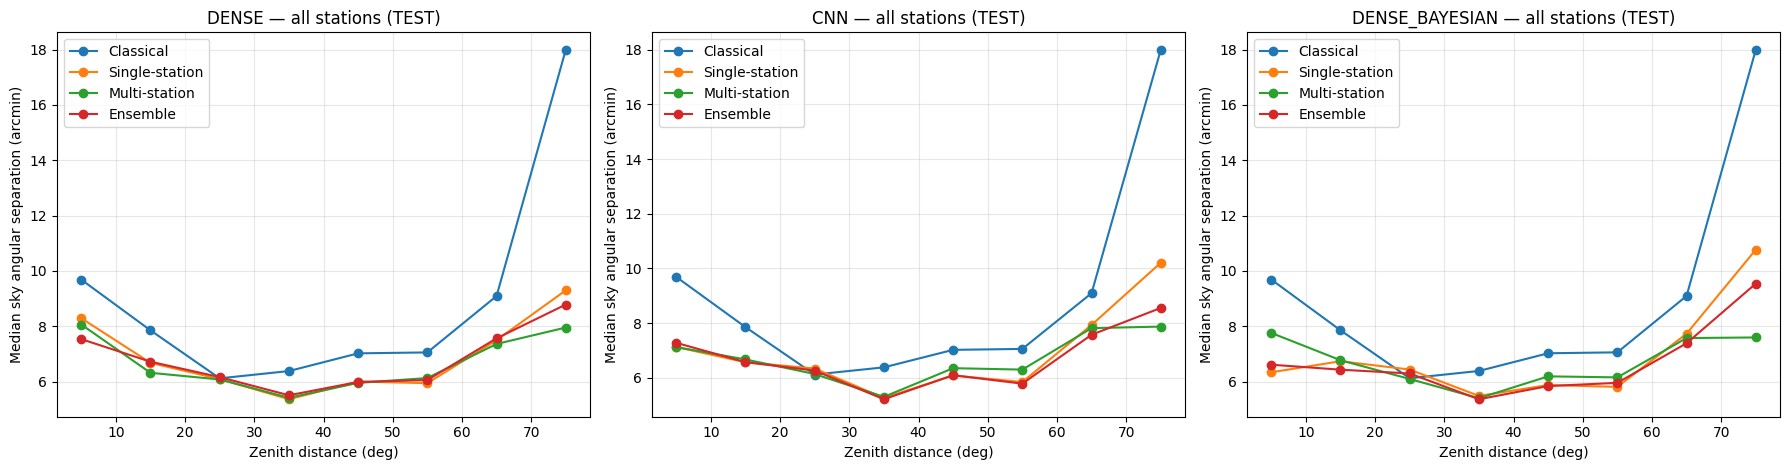

In [18]:
# Si la sesión se reinició, cargar los errores ya guardados (no hace falta reentrenar)
if 'PUNTOS' not in globals():
    PUNTOS = pd.read_csv(os.path.join(CARPETA, "errores_test_por_punto.csv"))
MODELOS_PLOT = list(dict.fromkeys(PUNTOS['modelo']))
METODOS = ['caldas', 'clasico', 'single', 'multi', 'blend']

PUNTOS['banda_z'] = pd.cut(PUNTOS['zenith'], [0, 30, 50, 60, 70, 80, 90])
por_z = PUNTOS.groupby(['modelo', 'banda_z'], observed=True).agg(
    N=('clasico', 'size'), **{m: (m, 'median') for m in METODOS})
display(por_z.round(2))
por_z.to_csv(os.path.join(CARPETA, "error_por_cenit.csv"))

edges = np.arange(0, 91, 10); cen = edges[:-1] + 5
fig, axs = plt.subplots(1, len(MODELOS_PLOT), figsize=(6*len(MODELOS_PLOT), 4.8), squeeze=False)
for ax, model_name in zip(axs[0], MODELOS_PLOT):
    P = PUNTOS[PUNTOS['modelo'] == model_name]
    for m, lab in [('clasico', 'Classical'), ('single', 'Single-station'),
                   ('multi', 'Multi-station'), ('blend', 'Ensemble')]:
        y = [P.loc[(P['zenith'] >= lo) & (P['zenith'] < hi), m].median()
             if ((P['zenith'] >= lo) & (P['zenith'] < hi)).sum() >= 5 else np.nan for lo, hi in zip(edges[:-1], edges[1:])]
        ax.plot(cen, y, 'o-', label=lab)
    ax.set_title(f'{model_name} — all stations (TEST)'); ax.set_xlabel('Zenith distance (deg)')
    ax.set_ylabel('Median sky angular separation (arcmin)'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(CARPETA, "error_vs_cenit_red_completa.png"), dpi=300, bbox_inches='tight')
plt.show()

## 5.5. Comparación de modelos (toda la red, test)

In [19]:
comp = global_tab.reset_index().pivot(index='modelo', columns='método', values=['mediana', 'MAE', 'RMSE'])
comp = comp.reindex(columns=METODOS, level=1)
display(comp.round(2))
comp.to_csv(os.path.join(CARPETA, "comparacion_modelos.csv"))
display(pd.DataFrame({'archivos guardados en': [CARPETA], 'n': [len(os.listdir(CARPETA))]}))

mediana                               MAE                       \
método          caldas clasico single multi blend caldas clasico single multi   
modelo                                                                          
CNN               13.8    7.27   6.26  6.38  6.27  27.76    9.51   8.41  8.46   
DENSE             13.8    7.27   6.25  6.18  6.20  27.76    9.51   8.49  8.41   
DENSE_BAYESIAN    13.8    7.27   6.21  6.35  6.22  27.76    9.51   8.52  8.52   

                       RMSE                               
método         blend caldas clasico single  multi  blend  
modelo                                                    
CNN             8.38  51.98   12.61  11.52  11.53  11.50  
DENSE           8.42  51.98   12.61  11.66  11.54  11.58  
DENSE_BAYESIAN  8.43  51.98   12.61  11.69  11.59  11.58

,archivos guardados en,n
0,/content/drive/MyDrive/InvestigacionesPropias/...,64
